In [1]:
import omicverse as ov
import scanpy as sc
import matplotlib.pyplot as plt
ov.plot_set(font_path='Arial')
sc.settings.set_figure_params(dpi=300, vector_friendly=True)
plt.rcParams['pdf.fonttype'] = 42
plt.rcParams['ps.fonttype'] = 42

/opt/miniforge/envs/omicverse_working/lib/python3.11/site-packages/scanpy/_utils/__init__.py:33: FutureWarning: `__version__` is deprecated, use `importlib.metadata.version('anndata')` instead.
  from anndata import __version__ as anndata_version
/opt/miniforge/envs/omicverse_working/lib/python3.11/site-packages/scanpy/__init__.py:24: FutureWarning: `__version__` is deprecated, use `importlib.metadata.version('anndata')` instead.
  if Version(anndata.__version__) >= Version("0.11.0rc2"):
/opt/miniforge/envs/omicverse_working/lib/python3.11/site-packages/scanpy/readwrite.py:16: FutureWarning: `__version__` is deprecated, use `importlib.metadata.version('anndata')` instead.
  if Version(anndata.__version__) >= Version("0.11.0rc2"):


/opt/miniforge/envs/omicverse_working/lib/python3.11/site-packages/louvain/__init__.py:54: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import get_distribution, DistributionNotFound


/opt/miniforge/envs/omicverse_working/lib/python3.11/site-packages/requests/__init__.py:113: RequestsDependencyWarning: urllib3 (2.6.3) or chardet (7.1.0)/charset_normalizer (3.4.3) doesn't match a supported version!
  warnings.warn(
/opt/miniforge/envs/omicverse_working/lib/python3.11/site-packages/anndata/__init__.py:70: FutureWarning: Importing read_loom from `anndata` is deprecated. Import anndata.io.read_loom instead.
  return module_get_attr_redirect(attr_name, deprecated_mapping=_DEPRECATED)


🔬 Starting plot initialization...
Using already downloaded Arial font from: /tmp/omicverse_arial.ttf


Registered as: Arial
🧬 Detecting GPU devices…
✅ NVIDIA CUDA GPUs detected: 8
    • [CUDA 0] NVIDIA GeForce RTX 4090 D
      Memory: 23.5 GB | Compute: 8.9
    • [CUDA 1] NVIDIA GeForce RTX 4090 D
      Memory: 23.5 GB | Compute: 8.9
    • [CUDA 2] NVIDIA GeForce RTX 4090 D
      Memory: 23.5 GB | Compute: 8.9
    • [CUDA 3] NVIDIA GeForce RTX 4090 D
      Memory: 23.5 GB | Compute: 8.9
    • [CUDA 4] NVIDIA GeForce RTX 4090 D
      Memory: 23.5 GB | Compute: 8.9
    • [CUDA 5] NVIDIA GeForce RTX 4090 D
      Memory: 23.5 GB | Compute: 8.9
    • [CUDA 6] NVIDIA GeForce RTX 4090 D
      Memory: 23.5 GB | Compute: 8.9
    • [CUDA 7] NVIDIA GeForce RTX 4090 D
      Memory: 23.5 GB | Compute: 8.9

   ____            _     _    __                  
  / __ \____ ___  (_)___| |  / /__  _____________ 
 / / / / __ `__ \/ / ___/ | / / _ \/ ___/ ___/ _ \ 
/ /_/ / / / / / / / /__ | |/ /  __/ /  (__  )  __/ 
\____/_/ /_/ /_/_/\___/ |___/\___/_/  /____/\___/                                           

In [2]:
from pathlib import Path
import importlib.util
import fitz
import pandas as pd
from IPython.display import Image as IPyImage, display

SCRIPT_PATH = Path('/data/hulei/OmicOS/OmicOS_10/scripts/build_ignite_single_roi_benchmark.py')
spec = importlib.util.spec_from_file_location('ignite_benchmark', SCRIPT_PATH)
bench = importlib.util.module_from_spec(spec)
spec.loader.exec_module(bench)

bench.ensure_dirs()
bench.remove_obsolete_outputs()
bench.setup_style()

def display_pdf_page(pdf_path, zoom=1.5):
    doc = fitz.open(str(pdf_path))
    pix = doc[0].get_pixmap(matrix=fitz.Matrix(zoom, zoom), alpha=False)
    display(IPyImage(data=pix.tobytes('png')))

In [3]:
manifest = bench.ensure_external_inputs()
original_image, original_gt, original_pred = bench.load_ignite_arrays()
image, gt, pred, roi_extent = bench.crop_to_annotation_roi(original_image, original_gt, original_pred)
tiles = bench.build_tile_calls(gt, pred)
metrics = bench.build_benchmark_metrics(gt, pred, tiles)
roc_df = bench.build_tile_roc_curve(tiles)
coverage = bench.build_coverage_summary(original_image, original_gt, image, gt, pred, tiles, roi_extent)

tables = {'manifest': manifest, 'tiles': tiles, 'metrics': metrics, 'coverage': coverage, 'roc': roc_df}
bench.save_tables(tables)

print(f'Analysis image: {image.shape[1]} x {image.shape[0]} px')
print(f'Scored tiles: {len(tiles)}')
metrics.loc[metrics['level'].eq('tile')]

Analysis image: 1050 x 1017 px
Scored tiles: 72


   level     metric      value
12  tile         tp  46.000000
13  tile         fp   0.000000
14  tile         fn   3.000000
15  tile         tn  23.000000
16  tile  precision   1.000000
17  tile     recall   0.938776
18  tile         f1   0.968421
19  tile       dice   0.968421
20  tile        iou   0.938776
21  tile   accuracy   0.958333
22  tile      auroc   0.987134
23  tile      auprc   0.992664

Panel A: Tile-level AUROC curve

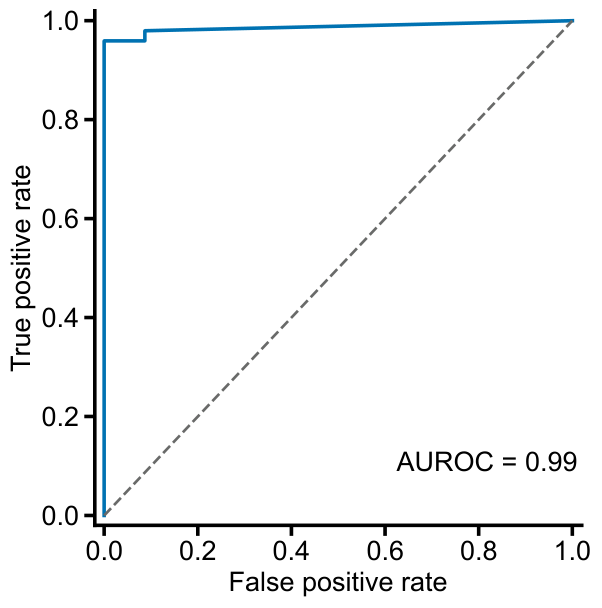

In [4]:
fig, ax = plt.subplots(figsize=(6, 6))
bench.plot_tile_auroc(ax, roc_df, metrics)
fig.tight_layout()
panel_path = bench.PANEL_DIR / 'supp_domain_cancer_A_tile_auroc.pdf'
fig.savefig(panel_path, dpi=300, bbox_inches='tight')
plt.close(fig)
display_pdf_page(panel_path)

Panel B: IGNITE annotated ROI overlay

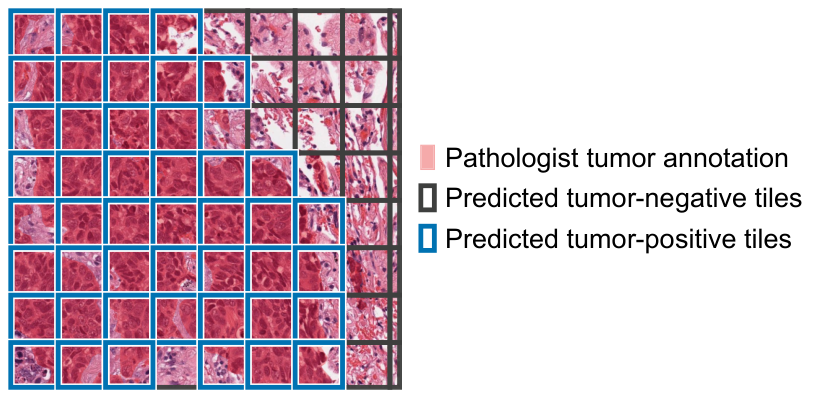

In [5]:
fig, ax = plt.subplots(figsize=(6, 6))
bench.plot_overlay(ax, image, gt, tiles)
fig.subplots_adjust(left=0.02, right=0.62, bottom=0.02, top=0.98)
panel_path = bench.PANEL_DIR / 'supp_domain_cancer_B_ignite_overlay.pdf'
fig.savefig(panel_path, dpi=300, bbox_inches='tight')
plt.close(fig)
display_pdf_page(panel_path)

Panel C: Tile-level confusion matrix

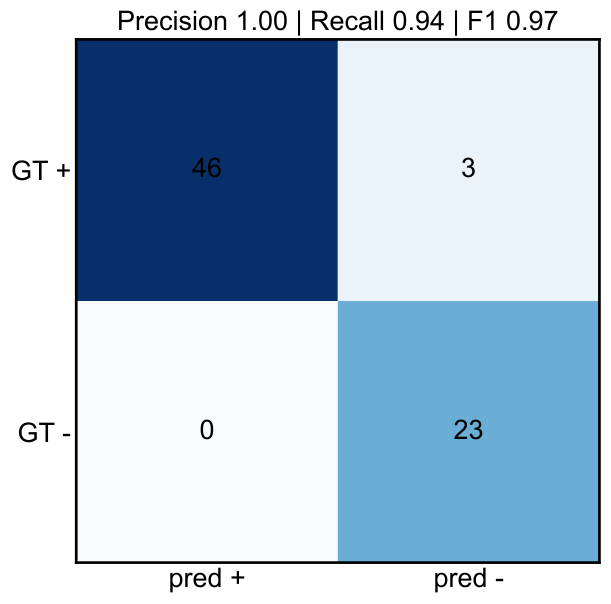

In [6]:
fig, ax = plt.subplots(figsize=(6, 6))
bench.plot_confusion_metrics(ax, metrics, tiles)
fig.tight_layout()
panel_path = bench.PANEL_DIR / 'supp_domain_cancer_C_tile_confusion_metrics.pdf'
fig.savefig(panel_path, dpi=300, bbox_inches='tight')
plt.close(fig)
display_pdf_page(panel_path)

Composite supplementary figure assembled from panels A-C

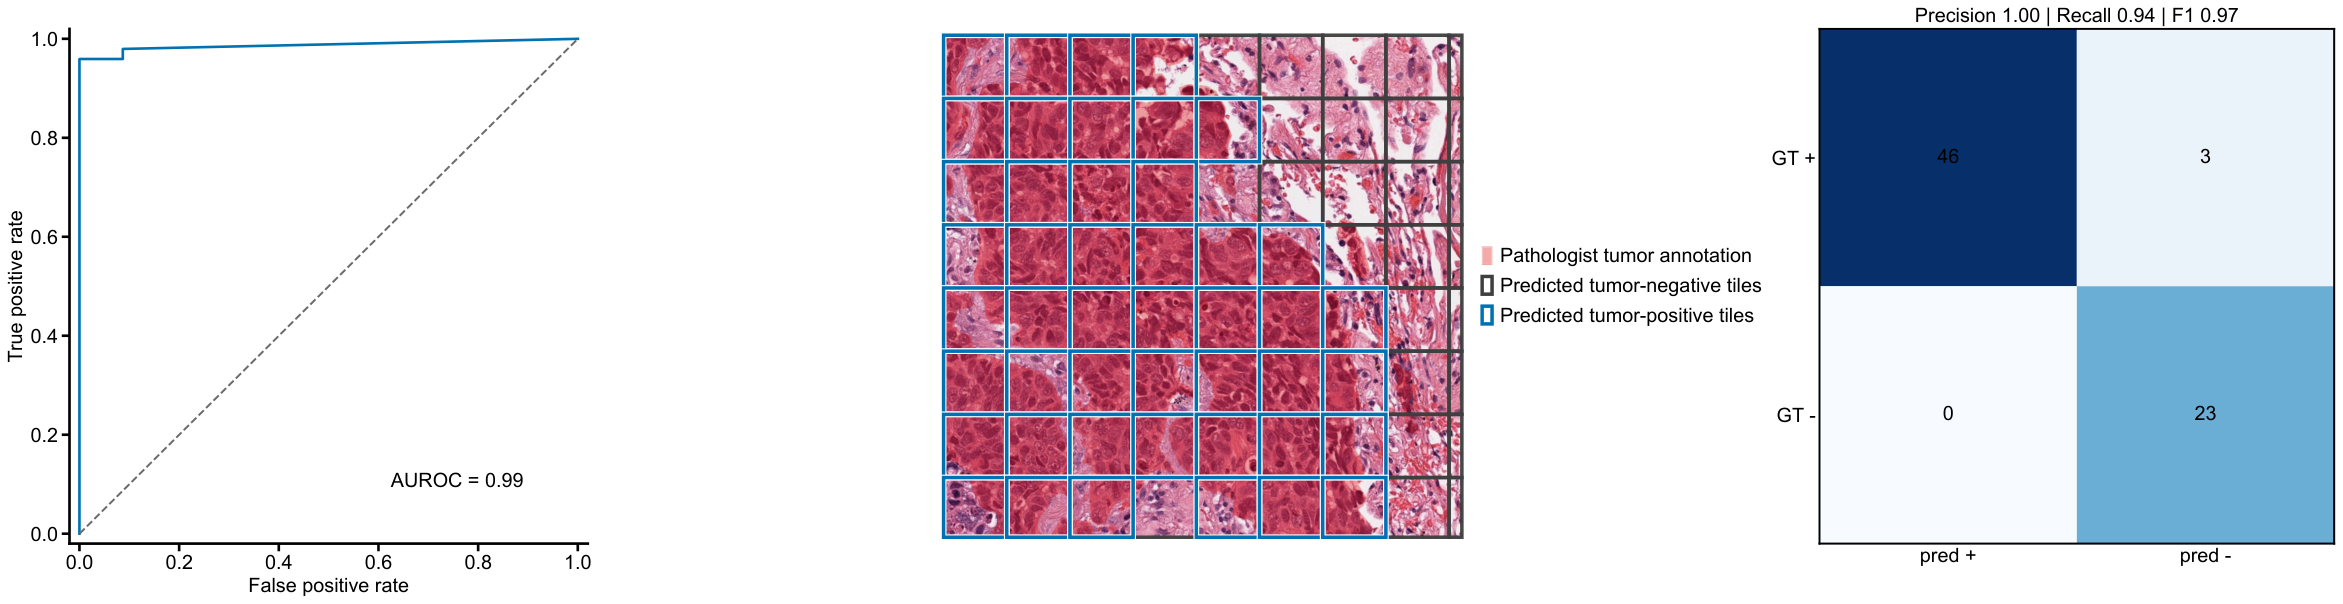

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(30, 8))
bench.plot_tile_auroc(axes[0], roc_df, metrics)
bench.plot_overlay(axes[1], image, gt, tiles)
bench.plot_confusion_metrics(axes[2], metrics, tiles)
fig.tight_layout()
figure_path = bench.FIG_DIR / 'supp_fig_domain_cancer_review.pdf'
fig.savefig(figure_path, dpi=300, bbox_inches='tight')
plt.close(fig)
display_pdf_page(figure_path, zoom=1.1)